# 从零构建 GPT — 完整教学笔记

本 notebook 用 **PyTorch** 从零实现一个迷你 **GPT** 语言模型，在 **Tiny Shakespeare**（`input.txt`）上训练，学习「预测下一个字符」。



# demo和gpt区别点

| notebook        | 真正 GPT                        |
| ------------------- | ------------------------------ |
| Tiny Shakespeare    | 大规模网页、书籍、代码、文章数据         |
| 字符级 token        | BPE / subword token            |
| Mini GPT            | 巨大的 decoder-only Transformer |
| 预测下一个字符      | 预测下一个 token                |
| Cross entropy loss  | Cross entropy loss             |
| AdamW 训练          | AdamW 或类似优化器              |
| causal mask         | causal mask                    |
| self-attention      | masked self-attention          |

---
## 1️⃣ 环境与依赖

| 库 | 用途 |
|---|---|
| `torch` | 张量计算 + 自动求导 |


In [8]:
import torch
import torch.nn as nn
from torch.nn import functional as F
import matplotlib.pyplot as plt
import numpy as np

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'使用设备: {device}')


使用设备: cpu


---
## 2️⃣ 加载数据集

使用 **Tiny Shakespeare** 数据集（`input.txt`，约 1MB），莎士比亚英文戏剧文本。

字符级分词：每个字符对应一个 ID，词表约 65 个字符。简单直观，适合教学。


In [9]:
with open('input.txt', 'r', encoding='utf-8') as f:
    text = f.read()

print(f'数据集字符数: {len(text):,}')
print(f'\n前 200 个字符预览:\n{text[:200]}')


数据集字符数: 1,115,394

前 200 个字符预览:
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you


---
## 3️⃣ 构建字符级分词器

模型只能处理数字，因此需要 **Tokenizer** 把文本映射为整数序列。

| 方案 | 词表大小 | 本 notebook |
|------|----------|-------------|
| 字符级 | ~65 | ✅ 使用 |
| BPE (GPT-2) | 50257 | 工程优化，后续可扩展 |


不同分词方式对比：教学 vs 工业实践

**本 Notebook** 采用 <span style="font-size:16px; font-weight:bold">字符级分词</span>：词表很小（约65个），实现简单，适合教学与实验，便于直接看到字符与ID的映射。
字符级分词器是“一个字符一个ID”，只能逐字符编码。

工业级比如 BPE（Byte Pair Encoding）分词可以把常见词、子词、短语编码成一个 token，能更高效理解和生成文本、更好压缩信息。BPE 会有“组合”token，比如“the”、“tion”等整体编码，不只是单字符。



In [10]:
chars = sorted(list(set(text)))
vocab_size = len(chars)
print(f'词表大小: {vocab_size}')
print(f'全部字符: {"".join(chars)}')

stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}
encode = lambda s: [stoi[c] for c in s]
decode = lambda l: ''.join([itos[i] for i in l])

print(f'\n编码示例: {encode("hii there")}')
print(f'解码验证: {decode(encode("hii there"))}')

# 这段代码的作用是：把全部文本字符（字符串）根据分词器编码成整数序列（token id），
# 然后用 torch.tensor 转成 PyTorch 张量，方便后续送给模型训练。
data = torch.tensor(encode(text), dtype=torch.long)
print(f'\nToken 张量形状: {data.shape}')


print(f'\n编码示例: {encode("I am at Jinan University")}')
print(f'解码验证: {decode(encode("I am at Jinan University"))}')

词表大小: 65
全部字符: 
 !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz

编码示例: [46, 47, 47, 1, 58, 46, 43, 56, 43]
解码验证: hii there

Token 张量形状: torch.Size([1115394])

编码示例: [21, 1, 39, 51, 1, 39, 58, 1, 22, 47, 52, 39, 52, 1, 33, 52, 47, 60, 43, 56, 57, 47, 58, 63]
解码验证: I am at Jinan University


---
## 4️⃣ 划分训练集与验证集

- **训练集 (90%)**：模型学习用
- **验证集 (10%)**：评估泛化能力

训练 loss 低、验证 loss 高 → **过拟合**。


In [11]:
n = int(0.9 * len(data))
train_data = data[:n]
val_data = data[n:]
print(f'训练集: {len(train_data):,} tokens')
print(f'验证集: {len(val_data):,} tokens')


训练集: 1,003,854 tokens
验证集: 111,540 tokens


---
## 5️⃣ 理解训练数据格式

语言模型任务：**给定前文，预测下一个 token**。

```
输入 x: [t0, t1, t2, ...]
目标 y: [t1, t2, t3, ...]   ← 右移一位
```

- **block_size**：一次能看到的最大上下文长度
- **batch_size**：并行处理多少条独立序列


In [12]:
block_size = 8
x = train_data[:block_size]
y = train_data[1:block_size + 1]

print(f'输入: {x.tolist()}')
print(f'目标: {y.tolist()}')
print(f'解码: {repr(decode(x.tolist()))} -> {repr(decode(y.tolist()))}')
print()
for t in range(block_size):
    context = x[:t + 1]
    target = y[t]
    ctx_dec = decode(context.tolist())
    tgt_dec = decode([target.item()])
    print(f'  输入 {context.tolist()} -> 预测 {target.item()}  |  {repr(ctx_dec)} -> {repr(tgt_dec)}')


输入: [18, 47, 56, 57, 58, 1, 15, 47]
目标: [47, 56, 57, 58, 1, 15, 47, 58]
解码: 'First Ci' -> 'irst Cit'

  输入 [18] -> 预测 47  |  'F' -> 'i'
  输入 [18, 47] -> 预测 56  |  'Fi' -> 'r'
  输入 [18, 47, 56] -> 预测 57  |  'Fir' -> 's'
  输入 [18, 47, 56, 57] -> 预测 58  |  'Firs' -> 't'
  输入 [18, 47, 56, 57, 58] -> 预测 1  |  'First' -> ' '
  输入 [18, 47, 56, 57, 58, 1] -> 预测 15  |  'First ' -> 'C'
  输入 [18, 47, 56, 57, 58, 1, 15] -> 预测 47  |  'First C' -> 'i'
  输入 [18, 47, 56, 57, 58, 1, 15, 47] -> 预测 58  |  'First Ci' -> 't'


 **💡 解读：** 自回归（autoregressive）是一种序列建模方法：每一步都用前面已知的 token 来预测下一个 token。也就是说，模型一次只预测序列中的一个位置，并且预测时只能看到当前位置之前的内容。这种方式通过不断滑动窗口，逐步将已知历史输入到模型中，实现对整个序列的生成和建模。

用前面已知的 token 预测下一个 token，每往后滑动一步多一个训练样本。


---
## 6️⃣ 构建数据加载器

每次训练随机采样 `batch_size` 条长度为 `block_size` 的序列：

```
x shape: (batch_size, block_size)
y shape: (batch_size, block_size)
```


In [13]:
batch_size = 4    # 每个 batch 包含多少条独立序列
block_size = 8    # 每条序列的长度

def get_batch(split):
    # 按照 split（'train' 或 'val'）选择数据
    data_split = train_data if split == 'train' else val_data
    # 随机采样 batch_size 个起点索引（保证序列不会越界）
    ix = torch.randint(len(data_split) - block_size, (batch_size,))
    # 构造输入 x: 每个样本起点为 i，长度为 block_size
    x = torch.stack([data_split[i:i + block_size] for i in ix])
    # 构造目标 y: 对应 x 右移一位，用来做下一个 token 的预测
    y = torch.stack([data_split[i + 1:i + block_size + 1] for i in ix])

    return x.to(device), y.to(device)

xb, yb = get_batch('train')
print(f'x: {xb.shape}, y: {yb.shape}, device: {xb.device}')
print("输入 xb:") 
print(xb)

print()

print("目标 yb:")
print(yb)

print("\n解读四个 batch（decode）:")
for b in range(batch_size): # batch dimension
    for t in range(block_size): # time dimension
        context = xb[b, :t+1]
        target = yb[b,t]
        print(f"when input is {context.tolist()} the target: {target}")

x: torch.Size([4, 8]), y: torch.Size([4, 8]), device: cpu
输入 xb:
tensor([[ 0,  0, 31, 27, 25, 17, 30, 31],
        [15, 20, 13, 30, 16,  1, 21, 21],
        [47, 51, 43,  1, 58, 53,  1, 44],
        [ 1, 63, 53, 59,  1, 45, 59, 47]])

目标 yb:
tensor([[ 0, 31, 27, 25, 17, 30, 31, 17],
        [20, 13, 30, 16,  1, 21, 21, 10],
        [51, 43,  1, 58, 53,  1, 44, 59],
        [63, 53, 59,  1, 45, 59, 47, 50]])

解读四个 batch（decode）:
when input is [0] the target: 0
when input is [0, 0] the target: 31
when input is [0, 0, 31] the target: 27
when input is [0, 0, 31, 27] the target: 25
when input is [0, 0, 31, 27, 25] the target: 17
when input is [0, 0, 31, 27, 25, 17] the target: 30
when input is [0, 0, 31, 27, 25, 17, 30] the target: 31
when input is [0, 0, 31, 27, 25, 17, 30, 31] the target: 17
when input is [15] the target: 20
when input is [15, 20] the target: 13
when input is [15, 20, 13] the target: 30
when input is [15, 20, 13, 30] the target: 16
when input is [15, 20, 13, 30, 16] the t

---
## 7️⃣ 最简模型：Bigram 语言模型

只看**当前字符**预测下一个，**完全忽略上下文** —— 这是 Attention 要解决的起点问题。

```
输入 't' → 查表 → 预测下一个字符的概率
（不管前面是 'Firs' 还是别的什么）
```

#### Bigram 的「bi」是什么意思？

**Bigram** = **bi**（二）+ **gram**（单元），即 **2-gram（二元组）**：只建模 **「当前字符 → 下一个字符」** 这一对，不看更前面的内容。

| 名称 | 含义 | 预测时看多少前文 |
|------|------|------------------|
| unigram | 1-gram | 不看前文，只统计每个字符本身多常见 |
| **bigram** | **2-gram** | **只看当前 1 个字符** |
| trigram | 3-gram | 看前 2 个字符 |

#### 条件概率

Bigram 估计的就是：

$$P(x_{t+1} \mid x_t)$$

即 **在已知当前字符 $x_t$ 的条件下，下一个字符 $x_{t+1}$ 是什么**。例如 `'t' 后面接什么字母概率最大` 就是在算 $P(\cdot \mid \text{'t'})$。

统计版做法：在语料里数 `(h, e)` 出现几次，再归一化：

$$P(\text{'e'} \mid \text{'h'}) = \frac{\text{count(h, e)}}{\sum_{c}\text{count(h, }c\text{)}}$$


比如对于文本 "hello world. hello deep learning.",
我们可以统计每个字符后面接什么字符的频率（bigram）：

例如 'h' 后面跟 'e' 的次数，

'e' 后面可能跟 'l' 或 ' '，

'l' 后面可能跟 'l'、'o' 或 '.'，

以此类推，
构成如下 bigram 转移矩阵（伪例子）：

'h' → 'e': 2 次

'e' → 'l': 3 次, 'e' → ' ': 2 次

'l' → 'l': 2 次, 'l' → 'o': 2 次, 'l' → '.': 1 次

'o' → ' ': 2 次, 'o' → 'r': 1 次

然后每次看到一个字符（比如 'l'），
只根据这个字符查表，选择下一个最可能出现的字符进行预测，






In [14]:
torch.manual_seed(1337)  # 固定随机种子，保证每次运行结果一致

class BigramLanguageModel(nn.Module):
    """
    Bigram 语言模型：只看「当前字符」，预测「下一个字符」。
    整张模型就是一张 vocab_size × vocab_size 的查表矩阵。
    """

    def __init__(self, vocab_size):
        super().__init__()
        # 输入 token i → 查第 i 行 → 得到下一个 token 的 logits（长度 vocab_size）
        self.token_embedding_table = nn.Embedding(vocab_size, vocab_size)

    def forward(self, idx, targets=None):
        # idx: (B, T)  一批字符序列
        logits = self.token_embedding_table(idx)  # (B, T, C)，C = vocab_size

        if targets is None:
            return logits, None  # 推理/生成：不算 loss

        # 训练：每个位置预测下一个字符，用交叉熵
        B, T, C = logits.shape
        loss = F.cross_entropy(
            logits.view(B * T, C),   # 展平成 (B*T, C)
            targets.view(B * T),     # 展平成 (B*T,)
        )
        return logits, loss

    def generate(self, idx, max_new_tokens):
        """自回归生成：反复「看最后一个字符 → 采样下一个 → 拼到末尾」"""
        for _ in range(max_new_tokens):
            logits, _ = self(idx)           # 对整个序列前向（bigram 实际只用最后一个）
            logits = logits[:, -1, :]         # 只取最后一个位置的预测 (B, C)
            probs = F.softmax(logits, dim=-1)
            idx_next = torch.multinomial(probs, num_samples=1)  # (B, 1)
            idx = torch.cat((idx, idx_next), dim=1)             # 序列变长 1
        return idx


# ── 下面 4 行：实例化 → 前向验证 → 打印形状/loss → 未训练时随机生成 ──

m = BigramLanguageModel(vocab_size).to(device)

# xb: 输入序列  yb: 对应的「下一个字符」目标（来自前面 get_batch）
logits, loss = m(xb, yb)
print(f'logits: {logits.shape}, 初始 loss: {loss.item():.4f} (理论值 ≈ {np.log(vocab_size):.2f})')

print('\n未训练生成:')
# 从 token 0（词表第一个字符）出发，生成 100 个字符，decode 成可读文本
print(decode(m.generate(torch.zeros((1, 1), dtype=torch.long, device=device), 100)[0].tolist()))


logits: torch.Size([4, 8, 65]), 初始 loss: 4.6716 (理论值 ≈ 4.17)

未训练生成:

SKIcLT;AcELMoTbvZv C?nq-QE33:CJqkOKH-q;:la!oiywkHjgChzbQ?u!3bLIgwevmyFJGUGp
wnYWmnxKWWev-tDqXErVKLgJ


---
## 8️⃣ 训练 Bigram 模型

标准训练三步：采样 batch → 前向算 loss → 反向更新参数。


In [21]:
optimizer = torch.optim.AdamW(m.parameters(), lr=1e-3)

for step in range(1000):
    xb, yb = get_batch('train')
    _, loss = m(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

# 理论上，如果模型完全随机预测，每个类别的概率是均匀的（1/vocab_size）
# 此时的交叉熵理论值为 -log(1/vocab_size) = log(vocab_size)
theoretical_loss = np.log(vocab_size)
print(f'理论最大熵 loss: {theoretical_loss:.4f} (即完全随机猜测时的期望 loss)')
print(f'1000 步后 loss: {loss.item():.4f} (低于该值说明模型学到了一些规律)')
print('\n训练后生成:')
print(decode(m.generate(torch.zeros((1, 1), dtype=torch.long, device=device), 300)[0].tolist()))


理论最大熵 loss: 4.1744 (即完全随机猜测时的期望 loss)
1000 步后 loss: 2.8515 (低于该值说明模型学到了一些规律)

训练后生成:


Y!pake rwacked id t; whred k:
Yzghe.
Rjuprst binke f hovV; Spay.: isO:CHAy CKINrer,
WA th
Dosunore berm,
SXrat;ack's qpetctckt s lNSKIUWLLJ$ deposicea!
SGIB?Obor mealintimagede ser movver s,. h g ot a s, wind ngulff ve Vu!wamy na iravak:

LIthsinono s thasth bculou anthin,Ink'de and r yGo,
Jgantenq


---
## 9️⃣ 为什么需要 Self-Attention？

---

### 0. 读代码前先建立的直觉

Attention 是一种**通信机制**：可以把每个 token 看作有向图里的节点，彼此“观察”；每个节点从所有指向它的节点那里用**加权和**聚合信息，权重由具体数据决定。

Attention 也是一种**注意力汇聚**，它没有空间位置概念：本质上只是在算「向量之间的相似度」，根本不知道谁在前、谁在后。如果你把输入序列的顺序打乱，Attention 的输出结果向量也完全一样（只是对应位置变了）。因此，在将数据送入 Attention 之前，必须加上**位置编码**（Positional Encoding）——本 notebook 用 §12 的 `position_embedding_table` 实现。

**batch 维度**上，每个样本完全独立处理，不会彼此“交流”或看到对方的信息（这与 §5–§6 的 batch 训练一致）。

| 类型 | 含义 | 本 notebook |
|------|------|-------------|
| **Self-attention** | Q、K、V 都来自同一输入 $x$ | v4 及 GPT 使用 |

**Scaled attention**：在 softmax 前用 $1/\sqrt{d_k}$（本 notebook 里即 `head_size`）缩放注意力分数。当 Q、K 方差为 1 时，分数方差也保持在 1，softmax 不会过于尖锐——公式见下文 §9.4，权重矩阵可视化见 §10。

---

### 1. Bigram 的局限

上一节的 Bigram 只用当前位置的字符来预测下一个字符，完全无法利用前文的信息。
比如句子 `First Citizen:` 中，预测 `i`（在 `First` 之后）时：
- Bigram 只知道当前是 `t`，不知道前面有 `Firs`。
- 更理想的模型：应该能“看到”`F`、`i`、`r`、`s`，综合上下文预测下一个字符。

|     | Bigram             | Self-Attention                        |
|-----|--------------------|---------------------------------------|
| 看多远 | 只看当前 1 个字       | 看左边所有已出现的字                    |
| 上下文利用 | 无                | 按权重加权混合进当前向量                 |
| 谁做预测 | 查表直接出 logits  | Attention 融合上下文，lm_head做预测      |


---

### 2. Attention 到底做什么

GPT 用因果 Self-Attention：

- 每个位置只“看”左边和自己，不能偷看后面未来的 token。
- 当前字符作为 Query，计算和左边所有 Key 的注意力权重（相关性分数）。
- 用这些权重对 Value（内容向量）加权求和，融合为当前位置的新向量。

举例：句子 F i r s t。在第 4 位 t 上，Query 是 t，它注意力范围包括 F, i, r, s, t（自己和左边），不能看右侧未来的字符。

数学公式：

$$
\text{out}_t = w_F \cdot V_F + w_i \cdot V_i + w_r \cdot V_r + w_s \cdot V_s + w_t \cdot V_t
$$

- $w$ 是通过 $Q,K$ 计算 softmax 得到的权重；
- $V$ 是各个 token 的向量；
- $\text{out}_t$ 是融合后的向量，传递给后续层。

总结：Attention 负责“聚合前文”，最终预测动作（下一个字符是谁）是在 lm_head 里完成。

---

### 3. Attention 解决了什么问题

Self-Attention 的作用：让每个位置从（因果约束下的）其他位置“借信息”，更新自己的表示。
可以拆解为三步：

1. 谁需要信息？→ Query（我现在是什么、找什么上下文）
2. 谁能提供信息？→ Key（我能给出什么信息）
3. 信息内容是什么？→ Value（携带的内容向量）

过程：用 Query 与历史所有 Key 算相似度 → Softmax 权重 → 权重加权 Value 总和 → 得到融合上下文的新向量。

---

### 4. Attention 的标准公式

$$
\text{Attention}(Q, K, V) = \text{softmax}\left(\frac{QK^T}{\sqrt{d_k}} + \text{mask}\right) V
$$

- $QK^T$：所有 token 两两的相关性分数。
- mask：因果掩码，$j>i$ 的权重设为 $-\infty$，保证不能看未来（只用 $j \leq i$）。
- $\sqrt{d_k}$：缩放，防止 softmax 太极端。
- 乘 $V$：加权聚合内容。

---

### 5. 线性代数视角：Attention 本质是加权求和

把输入序列看作 $T$ 个 $C$ 维向量，堆成矩阵 $X$（形状 $(T,C)$）：

```
X = [ x_0 ]   # 第 0 个 token 的向量
    [ x_1 ]
    [ ... ]
    [ x_{T-1} ]
```

Self-Attention 每个位置 $i$ 的输出：

$$
\text{out}_i = \sum_{j=0}^{T-1} W_{ij} \cdot x_j
$$

即，矩阵式：

$$
\text{Out} = W \cdot X \quad (W: T \times T)
$$

$W_{ij}$ 是注意力权重——位置 $i$ 从位置 $j$“借”信息（因果掩码下，$j>i$ 时 $W_{ij}=0$）。

| 符号           | 含义                      |
|----------------|-------------------------|
| $W_{ij}$ 大      | 位置 $i$ 更关注 位置 $j$      |
| $W_{ij}=0$      | 位置 $i$ 完全忽略 位置 $j$    |
| $\sum_j W_{ij}=1$ | 输出是输入的加权平均           |

---

### 6. 不同 Attention 版本的区别

核心差别：$W$（注意力矩阵）怎么来，是否依赖输入，能否训练获得？

| 版本   | $W$ 怎么来的                             | 是否依赖输入 $X$ | 能否学习   |
|--------|---------------------------------------|----------------|------------|
| v1-v2  | 手写下三角+均匀权重                   | 否             | 否         |
| v3     | softmax(mask)，分数全为 0             | 否             | 否         |
| v4     | softmax(QK^T/√d)，QK来自输入的线性变换 | 是             | 是         |

下面用 4 个版本，从求均值一步步推到完整的 Attention。


---
### v1 → v2 → v3：权重矩阵 $W$ 是「写死的」

**共同目标**：位置 $t$ 的输出 = 位置 $0,1,\ldots,t$ 的向量的**加权平均**（因果约束：$W_{ij}=0$ 当 $j>i$）。

下面分三个 Part 实现同一件事，写法不同、作用不同；v3 结束后三者数值应完全一致。

> **关键**：v1–v3 里，$W$ 不随输入 $X$ 变化，也没有可训练参数——不管喂什么文本，每个位置对前文都是**均匀关注**。


#### Part 1 · v1：for 循环求均值

**作用**：最直觉的实现——对每个位置 $t$，把 $0\sim t$ 的 token 向量直接 `mean` 起来。

- 因果性靠切片 `x[b, :t+1]` 天然保证（只看左边 + 自己）
- 线性代数上等价于 $\text{Out} = W X$，但 $W$ **没有显式构造**，藏在循环里
- 缺点：双重 for 慢，且看不出 Attention 的「权重矩阵」长什么样


In [49]:
# 这段代码主要实现了“均值自回归（Causal Mean Aggregation）”：对于每个序列的每个位置 t，
# 都把当前位置及其左侧所有 token 向量做均值，作为新表示。

# 数学表达式如下：
# 设输入 x 的形状为 (B, T, C)，其中 B 是 batch size，T 是序列长度，C 是向量维度。
# 第 b 条序列第 t 个位置的新表示为：
#   xbow[b, t] = (1 / (t+1)) * sum_{k=0}^{t} x[b, k]
# 即对所有 k=0..t 的向量均匀平均。

torch.manual_seed(1337)
B, T, C = 4, 8, 2
x = torch.randn(B, T, C)  # X: (B, T, C)，B 条序列，每条 T 个 token

xbow = torch.zeros(B, T, C)
for b in range(B):
    for t in range(T):
        #   xbow[b, t] = (1/(t+1)) * sum_{k=0}^{t} x[b, k]
        xbow[b, t] = x[b, :t + 1].mean(0)  # 第 b 条序列，位置 t，聚合其前面及当前 token

print('v1：xbow 形状:', xbow.shape)
print('batch 0、位置 3 的输出:', xbow[0, 3])

# 这里手动计算 x[0] 序列里第 0~3 个 token 的均值，验证上面 xbow[0, 3] 的结果
print('手算验证 mean(x[0,0:4]):', x[0, :4].mean(0))



v1：xbow 形状: torch.Size([4, 8, 2])
batch 0、位置 3 的输出: tensor([ 0.3504, -0.2238])
手算验证 mean(x[0,0:4]): tensor([ 0.3504, -0.2238])


#### Part 2 · v2：显式构造权重矩阵 $W$

把 v1 里隐式的均匀加权写成矩阵 **wei**，一次矩阵乘法算完：$\text{Out} = \text{wei} \cdot X$。

- `tril` → 下三角，$j>i$ 处权重为 0（因果 mask）
- 每行除以行和 → $\sum_j W_{ij}=1$
- 第 $i$ 行：位置 $0\sim i$ 各分 $\frac{1}{i+1}$（均匀）

> v1 用 `mean` 逐行算，v2 用矩阵乘一次算完；数学上相同，但浮点路径不同，`allclose` 需加 `atol=1e-5`（默认 `1e-8` 太严，差值约 `3e-8` 也会判 False）。


In [47]:
# version 2: using matrix multiply for a weighted aggregation
wei = torch.tril(torch.ones(T, T))
wei = wei / wei.sum(1, keepdim=True)
xbow2 = wei @ x  # (T, T) @ (B, T, C) → (B, T, C)
torch.allclose(xbow, xbow2, atol=1e-5)  # 默认 atol=1e-8 会因浮点误差误报 False


True

#### Part 3 · v3：用 softmax 得到同一个 $W$

换一条与 v4 **相同的计算路径**：`scores → mask → softmax → @ X`。可见位置分数全为 0 时，softmax 得到与 v2 **完全相同**的均匀下三角 wei。


In [48]:
# version 3: use Softmax
tril = torch.tril(torch.ones(T, T))
wei = torch.zeros((T, T))
wei = wei.masked_fill(tril == 0, float('-inf'))
wei = F.softmax(wei, dim=-1)
xbow3 = wei @ x
torch.allclose(xbow, xbow3, atol=1e-5)


True

---
### v4：Self-Attention —— $W$ 由数据算出，且可训练

v1–v3 的问题：**$W_{ij}$ 永远均匀**（只要 $j \le i$，大家权重一样）。  
真实语言里，预测 `'t'` 时应该更关注 `'s'`，而不是和 `'F'` 同等重要。

#### 线性代数上多了什么？

1. **$W$ 不再常数**，而是输入的函数：
   $$W = \text{softmax}\left(\frac{Q K^T}{\sqrt{d}} + \text{mask}\right)$$
2. **$Q, K, V$ 都是 $X$ 的线性变换**（可学习的矩阵乘法）：
   $$Q = X W_Q,\quad K = X W_K,\quad V = X W_V$$
3. **输出仍是矩阵乘法**，但聚合的是 $V$ 而不是 $X$：
   $$\text{Out} = W \cdot V$$

#### 「固定」vs「可学习」到底指什么？

| | v2（固定） | v4（可学习） |
|---|-----------|-------------|
| 权重 $W_{ij}$ | 人工设定，永远 $1/(i+1)$ | 由 $q_i \cdot k_j$ 算出，每个样本不同 |
| 依赖输入 $X$？ | ❌ | ✅ 换一段文本，$W$ 就变 |
| 可训练参数 | 无 | $W_Q, W_K, W_V$（`nn.Linear` 的权重） |
| 训练时发生什么 | — | 反向传播调整 $W_Q,W_K,W_V$，让「该关注的地方」权重变大 |

#### $q_i \cdot k_j$ 是什么？

就是两个向量的 **内积（点积）**：衡量「查询 $q_i$」和「键 $k_j$」有多匹配。  
内积大 → softmax 后 $W_{ij}$ 大 → 位置 i 多从位置 j 借信息。

**形状一览（单个 head）：**

```
X:   (B, T, C)
Q,K: (B, T, head)     ← X 右乘 W_Q, W_K
V:   (B, T, head)     ← X 右乘 W_V
scores: (B, T, T)     ← Q @ K^T，scores[b,i,j] = q_i · k_j
W:   (B, T, T)        ← softmax(scores + mask)，每行和为 1
Out: (B, T, head)     ← W @ V
```


In [ ]:
torch.manual_seed(1337)
B, T, C = 4, 8, 32
x = torch.randn(B, T, C)
head_size = 16

Wq = nn.Linear(C, head_size, bias=False)  
Wk = nn.Linear(C, head_size, bias=False)
Wv = nn.Linear(C, head_size, bias=False)

Q, K, V = Wq(x), Wk(x), Wv(x)

# ① 算分数矩阵 S = Q K^T / sqrt(d)   （内积表：谁和谁相关）
S = Q @ K.transpose(-2, -1) / head_size ** 0.5  # (B, T, T)
# ② 因果掩码 + softmax → 权重矩阵 W（每行概率分布）
W_attn = F.softmax(S.masked_fill(torch.tril(torch.ones(T, T)) == 0, float('-inf')), dim=-1)
# ③ Out = W @ V
out = W_attn @ V

print('--- v4 线性代数拆解 ---')
print(f'X:  {x.shape}  →  Q,K,V: {Q.shape}')
print(f'分数 S = QK^T: {S.shape}   (未归一化，可正可负)')
print(f'权重 W = softmax(S+mask): {W_attn.shape}   (每行和=1)')
print(f'输出 Out = W @ V: {out.shape}')

i = 3  # 看第 4 个 token
print(f'\n位置 i={i} 对前 4 个位置的权重 W[{i}, :4]:')
print(W_attn[0, i, :4])
print(f'权重之和 = {W_attn[0, i, :4].sum():.4f}')

# 对比 v2 的固定 W
W_fixed = torch.tril(torch.ones(T, T))
W_fixed = W_fixed / W_fixed.sum(1, keepdim=True)
print(f'\n对比 v2 固定权重 W_fixed[{i}, :4]: {W_fixed[i, :4]}  （均匀 0.25）')
print(f'v4 权重是否均匀? 否 —— 因为 S 来自可学习的 Q,K，不再是全 0')


--- v4 线性代数拆解 ---
X:  torch.Size([4, 8, 32])  →  Q,K,V: torch.Size([4, 8, 16])
分数 S = QK^T: torch.Size([4, 8, 8])   (未归一化，可正可负)
权重 W = softmax(S+mask): torch.Size([4, 8, 8])   (每行和=1)
输出 Out = W @ V: torch.Size([4, 8, 16])

位置 i=3 对前 4 个位置的权重 W[3, :4]:
tensor([0.2980, 0.4039, 0.1578, 0.1404], grad_fn=<SliceBackward0>)
权重之和 = 1.0000

对比 v2 固定权重 W_fixed[3, :4]: tensor([0.2500, 0.2500, 0.2500, 0.2500])  （均匀 0.25）
v4 权重是否均匀? 否 —— 因为 S 来自可学习的 Q,K，不再是全 0


# 用真实文本直觉理解


权重矩阵 **每一行** = 该行对应字符「从左边各位置借多少」；**下三角** = 因果掩码（$j > i$ 的权重为 0）。


所以：**权重是用来混合左边信息的，不是直接等于「下一个字的概率」。**
下面用 `"I'm at Jinan University."` 打印完整权重矩阵（行 = 谁在回头看，列 = 被借信息的是谁）。



In [13]:
# 用真实字符演示：attention 权重长什么样
# 读法：第 i 行 = 字符 i「回头看」左边各字符的权重；右上三角为 0 = 不能看未来

demo_text = "I'm at Jinan University."
demo_ids = torch.tensor(encode(demo_text), dtype=torch.long).unsqueeze(0)  # (1, T)
T_demo = demo_ids.shape[1]
C_demo = 16

emb = nn.Embedding(vocab_size, C_demo)
x_demo = emb(demo_ids)  # (1, T, C)

head_size = 8
Wq = nn.Linear(C_demo, head_size, bias=False)
Wk = nn.Linear(C_demo, head_size, bias=False)
Wv = nn.Linear(C_demo, head_size, bias=False)

q = Wq(x_demo)  # (1, T, head_size)
k = Wk(x_demo)  # (1, T, head_size)
v = Wv(x_demo)  # (1, T, head_size)

# ① 原始分数（还不是权重）→ ② mask 挡住未来 → ③ softmax 得到最终权重
scores = q @ k.transpose(-2, -1) / head_size ** 0.5  # (1, T, T)
tril_mask = torch.tril(torch.ones(T_demo, T_demo)).bool()
scores = scores.masked_fill(~tril_mask, float('-inf'))
wei_demo = F.softmax(scores, dim=-1)  # (1, T, T) ← 这才是最终注意力权重

chars = list(demo_text)
print('字符:', chars)
print('\n注意力权重矩阵（行=当前字回头看谁, 列=被借信息的是谁, 右上三角=未来=0）:')
print('      ', '  '.join(f'{c:>6}' for c in chars))
for i, c in enumerate(chars):
    row_vals = wei_demo[0, i].detach().cpu().tolist()
    row = '  '.join(f'{v:6.3f}' for v in row_vals)
    print(f'  {c:>3}  {row}')
print('\n→ 下三角：位置 i 只能 attend 到 j≤i（左边+自己）；权重行和=1，用于加权混合 V，不是下一个字的概率')


字符: ['I', "'", 'm', ' ', 'a', 't', ' ', 'J', 'i', 'n', 'a', 'n', ' ', 'U', 'n', 'i', 'v', 'e', 'r', 's', 'i', 't', 'y', '.']

注意力权重矩阵（行=当前字回头看谁, 列=被借信息的是谁, 右上三角=未来=0）:
            I       '       m               a       t               J       i       n       a       n               U       n       i       v       e       r       s       i       t       y       .
    I   1.000   0.000   0.000   0.000   0.000   0.000   0.000   0.000   0.000   0.000   0.000   0.000   0.000   0.000   0.000   0.000   0.000   0.000   0.000   0.000   0.000   0.000   0.000   0.000
    '   0.405   0.595   0.000   0.000   0.000   0.000   0.000   0.000   0.000   0.000   0.000   0.000   0.000   0.000   0.000   0.000   0.000   0.000   0.000   0.000   0.000   0.000   0.000   0.000
    m   0.342   0.382   0.276   0.000   0.000   0.000   0.000   0.000   0.000   0.000   0.000   0.000   0.000   0.000   0.000   0.000   0.000   0.000   0.000   0.000   0.000   0.000   0.000   0.000
        0.215   0.214   0.323   0.248   

---
## 🔟 Self-Attention 可视化


**多头 Attention（Multi-Head）**：

- 单 head 的权重矩阵 $W$ 是 $(T \times T)$；$n$ 个 head 就是 $n$ 个不同的 $W$ **并行**计算
- 每个 head 有独立的 $W_Q, W_K, W_V$，子空间维度 `head_size = n_embd // n_head`
- 输出：`concat(head_1, ..., head_n)` → 形状 `(B, T, n_embd)` → 再经 `proj` 线性层混合各 head 的信息

```
单 head:  Out = W @ V          shape (B, T, head_size)
多头:     Out = proj(cat(...)) shape (B, T, n_embd)
```
一个 head：更关注紧挨着的上一个字（相邻字符）

一个 head：更关注句首、段落开头

一个 head：更关注标点、空格等结构

一个 head：更关注重复出现的模式

多头 = 几个「专家」并行工作，各自算自己的注意力，最后把结果拼起来。


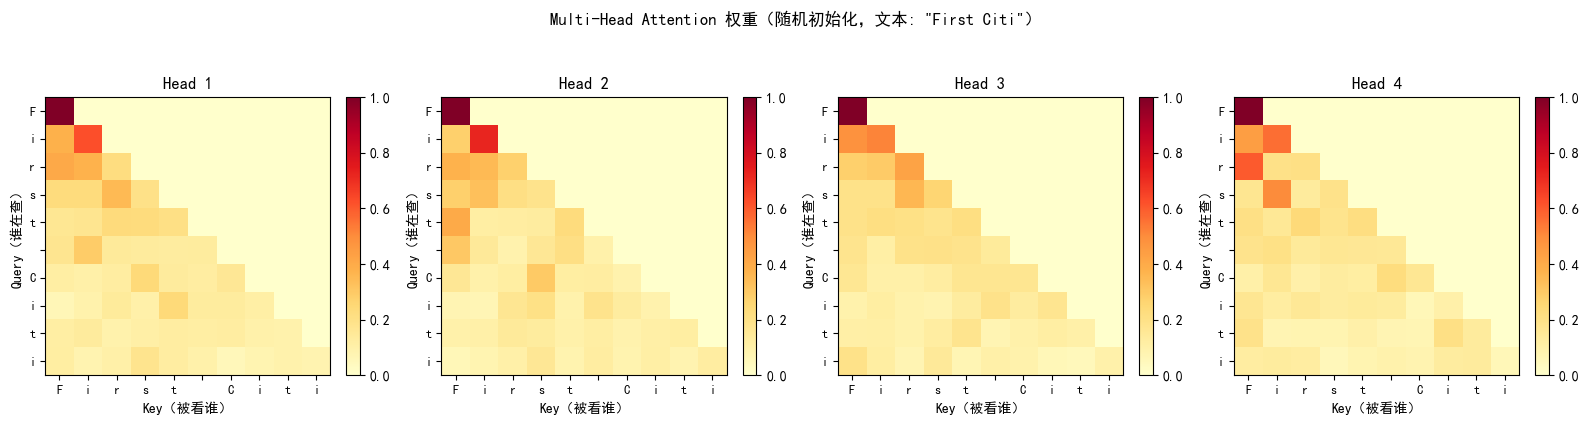

In [23]:
# 与后面完整 GPT 一致（§10 可单独运行，不依赖 §13）
n_embd, n_head = 64, 4

# 用真实莎士比亚片段演示（随机 W，只看注意力矩阵「形状」）
demo_text = "First Citi"
T = len(demo_text)
x = torch.randn(1, T, n_embd)
head_size = n_embd // n_head
tril = torch.tril(torch.ones(T, T))

# 为确保中文不乱码，调整 matplotlib 字体
import matplotlib
# 设置支持中文的字体（比如 SimHei 或 SimSun，需本机已安装或用常用的雅黑/msyh）
matplotlib.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'STSong', 'Arial Unicode MS', 'sans-serif']
matplotlib.rcParams['axes.unicode_minus'] = False  # 正常显示负号

fig, axes = plt.subplots(1, n_head, figsize=(16, 4))
for i in range(n_head):
    key = nn.Linear(n_embd, head_size, bias=False)
    query = nn.Linear(n_embd, head_size, bias=False)
    k, q = key(x), query(x)
    wei = F.softmax(
        (q @ k.transpose(-2, -1) / head_size ** 0.5).masked_fill(tril[:T, :T] == 0, float('-inf')),
        dim=-1,
    )
    im = axes[i].imshow(wei[0].detach().cpu().numpy(), cmap='YlOrRd', aspect='auto', vmin=0, vmax=1)
    axes[i].set_title(f'Head {i + 1}')
    axes[i].set_xticks(range(T))
    axes[i].set_yticks(range(T))
    axes[i].set_xticklabels(list(demo_text), fontsize=9)
    axes[i].set_yticklabels(list(demo_text), fontsize=9)
    axes[i].set_xlabel('Key（被看谁）')
    axes[i].set_ylabel('Query（谁在查）')
    plt.colorbar(im, ax=axes[i], fraction=0.046)
plt.suptitle(f'Multi-Head Attention 权重（随机初始化，文本: \"{demo_text}\"）', y=1.05)
plt.tight_layout()
plt.show()

### 怎么读这张热力图？

把它想成一张 **「谁在看谁」** 的表，而不是「下一个字概率表」。

| 图上元素 | 含义 |
|---------|------|
| **行（Query / 纵轴）** | 正在「查信息」的 token：*我现在站在这个位置，要从左边借上下文* |
| **列（Key / 横轴）** | 被「查」的 token：*谁能被我参考* |
| **格子颜色深浅** | 注意力权重 $w_{ij}$：行 $i$ 对列 $j$ 的重视程度（越深越大） |
| **一行所有格子加起来** | = 1（softmax 后的概率分配） |
| **右上角空白（上三角）** | 因果掩码：不能看**右边未来**，所以只有**下三角**有颜色 |

**和预测的关系：**

```
Attention 权重 W  →  加权混合 V  →  更新向量
                                      ↓
                               后面还有 FFN、更多层
                                      ↓
                               lm_head  →  预测下一个字符
```


**为什么有 4 张子图（多头）？**

每个 Head 有独立的 $W_Q, W_K, W_V$，相当于 4 个「专家」并行看同一段文字，但学到的关注模式可以不同（有的偏相邻字，有的偏标点/句首等）。


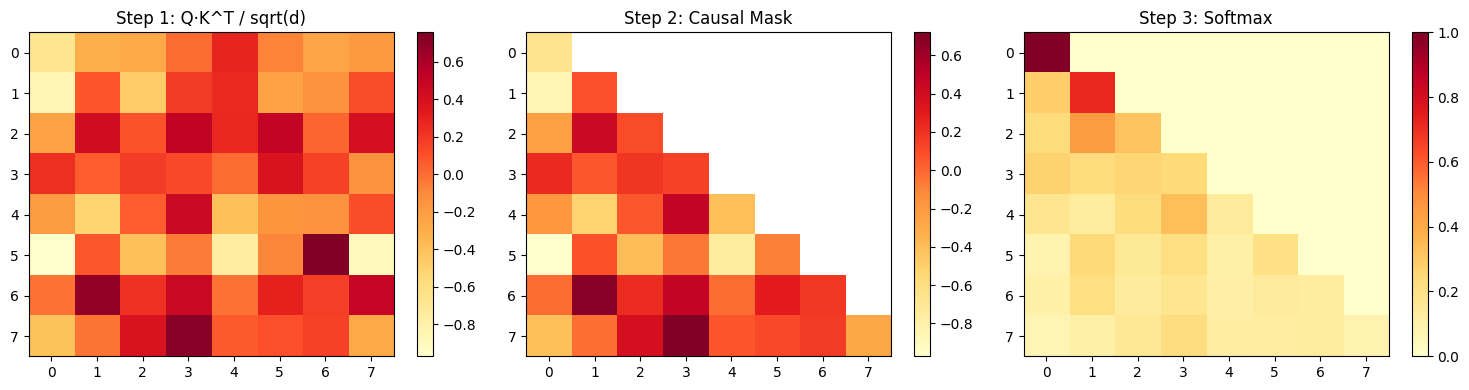

In [15]:
torch.manual_seed(1337)
B, T, C = 1, 8, 32
x = torch.randn(B, T, C)
head_size = 16
k = nn.Linear(C, head_size, bias=False)(x)
q = nn.Linear(C, head_size, bias=False)(x)
wei = q @ k.transpose(-2, -1) / head_size ** 0.5
tril = torch.tril(torch.ones(T, T))
wei_softmax = F.softmax(wei.masked_fill(tril == 0, float('-inf')), dim=-1)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
titles = ['Step 1: Q·K^T / sqrt(d)', 'Step 2: Causal Mask', 'Step 3: Softmax']
mats = [wei[0], wei.masked_fill(tril == 0, float('nan'))[0], wei_softmax[0]]
for ax, mat, title in zip(axes, mats, titles):
    im = ax.imshow(mat.detach().numpy(), cmap='YlOrRd', aspect='auto')
    ax.set_title(title)
    plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()


In [16]:
head_size = 16
k = torch.randn(4, 8, head_size)
q = torch.randn(4, 8, head_size)
wei = q @ k.transpose(-2, -1) / head_size ** 0.5
print(f'缩放后 wei 方差 ≈ {wei.var():.2f}（接近 1，softmax 不会饱和）')
print('\n小值 softmax（均匀）:', torch.softmax(torch.tensor([0.1, -0.2, 0.3, -0.2, 0.5]), dim=-1))
print('大值 softmax（one-hot，梯度消失）:', torch.softmax(torch.tensor([0.1, -0.2, 0.3, -0.2, 0.5]) * 8, dim=-1))


缩放后 wei 方差 ≈ 0.94（接近 1，softmax 不会饱和）

小值 softmax（均匀）: tensor([0.1925, 0.1426, 0.2351, 0.1426, 0.2872])
大值 softmax（one-hot，梯度消失）: tensor([0.0326, 0.0030, 0.1615, 0.0030, 0.8000])


---
## 1️⃣1️⃣ 层归一化（Layer Normalization）

对每个样本的特征维度归一化，稳定深层网络训练。Transformer 用 LayerNorm 而非 BatchNorm。

手写 demo 的 `gamma=1, beta=0`（未训练），所以均值/标准差接近 0 和 1，但不完全相等。训练时 `gamma, beta` 可学习。


In [17]:
class LayerNorm1d:
    def __init__(self, dim, eps=1e-5):
        self.eps = eps
        self.gamma = torch.ones(dim)
        self.beta = torch.zeros(dim)

    def __call__(self, x):
        xmean = x.mean(1, keepdim=True)
        xvar = x.var(1, keepdim=True)
        xhat = (x - xmean) / torch.sqrt(xvar + self.eps)
        return self.gamma * xhat + self.beta

torch.manual_seed(1337)
x = LayerNorm1d(100)(torch.randn(32, 100))
print(f'归一化后 — 每样本特征均值 ≈ {x.mean(1).mean():.4f}, 标准差 ≈ {x.std(1).mean():.4f}')


归一化后 — 每样本特征均值 ≈ -0.0000, 标准差 ≈ 1.0000


### 1️⃣2️⃣完整 GPT：组件怎么拼起来


一个完整的 GPT 模型处理和预测文本的流程如下：

1. **输入 token IDs (形状: [B, T])**
   - 首先输入一批文本，每个文本被切分成若干 token，每个 token 用唯一的整数 ID 表示。

2. **嵌入层：Token Embedding + Position Embedding**
   - 每个 token 的 ID 通过查表方式映射为一个稠密向量（`token_embedding_table`），用于表示词语意义。
   - 同时，每一个 token 在句子中的位置也有一个位置向量（`position_embedding_table`），体现位置信息。
   - 两种向量对应位置相加，得到每个 token 的初始向量表示。

3. **Transformer Block 堆叠（repeat n_layer 次）**
   - 每个 Block 包含如下子组件：
     a) LayerNorm（`ln1`）：先做归一化，稳定训练。

     b) 多头自注意力（`sa`）：每个 token 在 block_size 范围内关注左右文，混合信息。

     c) 残差连接：输入加到输出，防止梯度消失。

     d) LayerNorm（`ln2`）：再做一次归一化。

     e) 前馈神经网络（`ffwd`）：每个 token 独立做非线性变换。

     f) 残差连接：继续防止训练问题。
     
   - 多个这样的 Block 层叠，增强模型表达能力。

4. **输出层**
   - 经过所有 Block 的输出经过一次总的 LayerNorm（`ln_f`），有助于收敛。
   - 最后通过一个全连接层（`lm_head`）将每个 token 的最终向量映射为与词表等长的 logits，表示预测下一个 token 是每个词的概率。

5. **得到输出 logits**
   - 最终模型输出 logits，作为下一个字符/词的预测依据。

**模型各组件在代码中的变量：**
- Token Embedding: `token_embedding_table`
- Position Embedding: `position_embedding_table`
- Transformer Block: `blocks`（包括 `Block.ln1`、`Block.ln2`、`Block.sa`、`Block.ffwd`）
- 输出层: `ln_f`，`lm_head`

**组件对应变量 / 超参数一览：**

| 组件                | 代码变量                  | 说明 / 超参数                 |
|---------------------|--------------------------|-------------------------------|
| Token Embedding     | `token_embedding_table`  | vocab≈65 → 64 维（n_embd=64）  |
| Position Embedding  | `position_embedding_table` | 最长 32 个位置（block_size=32）|
| Multi-Head Attention| `Block.sa`               | 4 头，每头 16 维（n_head=4）  |
| Feed-Forward        | `Block.ffwd`             | 64 → 256 → 64                 |
| 重复层数            | `blocks`                 | n_layer = 4                   |
| 预测头              | `lm_head`                | 64 → vocab_size                |




In [18]:
# 超参数
batch_size = 16     
block_size = 32     
max_iters = 500     # 训练的最大迭代次数
eval_interval = 100 # 每隔多少步评估一次模型
learning_rate = 1e-3 
eval_iters = 200    # 评估时取多少个 batch 平均 loss
n_embd = 64         # 每个 token 的嵌入维度（embedding size）
n_head = 4          # 多头注意力的头数
n_layer = 4         # Transformer 的层数
dropout = 0.0      

torch.manual_seed(1337)

def get_batch(split):
    data_split = train_data if split == 'train' else val_data
    ix = torch.randint(len(data_split) - block_size, (batch_size,))
    x = torch.stack([data_split[i:i + block_size] for i in ix])
    y = torch.stack([data_split[i + 1:i + block_size + 1] for i in ix])
    return x.to(device), y.to(device)

# 不计算梯度，加速验证、节省内存
@torch.no_grad()
def estimate_loss():
    out = {}
    model.eval()
    for split in ['train', 'val']:
        losses = torch.zeros(eval_iters)
        for k in range(eval_iters):
            X, Y = get_batch(split)
            _, loss = model(X, Y)
            losses[k] = loss.item()
        out[split] = losses.mean()
    model.train()
    return out

class Head(nn.Module):
    def __init__(self, head_size):
        # 调用父类的__init__方法，确保nn.Module的初始化逻辑被正确执行
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        self.register_buffer('tril', torch.tril(torch.ones(block_size, block_size)))
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, T, C = x.shape
        k, q = self.key(x), self.query(x)
        wei = (q @ k.transpose(-2, -1)) * C ** -0.5
        wei = wei.masked_fill(self.tril[:T, :T] == 0, float('-inf'))
        wei = self.dropout(F.softmax(wei, dim=-1))
        return wei @ self.value(x)

class MultiHeadAttention(nn.Module):
    def __init__(self, num_heads, head_size):
        super().__init__()
        self.heads = nn.ModuleList([Head(head_size) for _ in range(num_heads)])
        self.proj = nn.Linear(n_embd, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([h(x) for h in self.heads], dim=-1)
        return self.dropout(self.proj(out))

class FeedForward(nn.Module):
    def __init__(self, n_embd):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd), nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd), nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)

class Block(nn.Module):
    def __init__(self, n_embd, n_head):
        super().__init__()
        head_size = n_embd // n_head
        self.sa = MultiHeadAttention(n_head, head_size)
        self.ffwd = FeedForward(n_embd)
        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x):
        x = x + self.sa(self.ln1(x))
        x = x + self.ffwd(self.ln2(x))
        return x

class GPT(nn.Module):
    def __init__(self):
        super().__init__()
        self.token_embedding_table = nn.Embedding(vocab_size, n_embd)
        self.position_embedding_table = nn.Embedding(block_size, n_embd)
        self.blocks = nn.Sequential(*[Block(n_embd, n_head) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        tok_emb = self.token_embedding_table(idx)
        pos_emb = self.position_embedding_table(torch.arange(T, device=device))
        x = self.blocks(tok_emb + pos_emb)
        x = self.ln_f(x)
        logits = self.lm_head(x)
        if targets is None:
            return logits, None
        return logits, F.cross_entropy(logits.view(B * T, -1), targets.view(B * T))

    def generate(self, idx, max_new_tokens):
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -block_size:]
            logits, _ = self(idx_cond)
            probs = F.softmax(logits[:, -1, :], dim=-1)
            idx = torch.cat((idx, torch.multinomial(probs, 1)), dim=1)
        return idx

model = GPT().to(device)
print(f'模型参数量: {sum(p.numel() for p in model.parameters()) / 1e6:.2f} M')


模型参数量: 0.21 M


---
## 1️⃣3️⃣ 训练 GPT

5000 步训练，每 100 步评估 train/val loss。CPU 上约需 10–40 分钟；demo 可将 `max_iters` 改为 500。


In [19]:
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)
train_losses, val_losses, steps_log = [], [], []

print('开始训练...')
for step in range(max_iters):
    if step % eval_interval == 0 or step == max_iters - 1:
        losses = estimate_loss()
        train_losses.append(losses['train'])
        val_losses.append(losses['val'])
        steps_log.append(step)
        print(f"  Step {step:5d}: train {losses['train']:.4f}, val {losses['val']:.4f}")
    xb, yb = get_batch('train')
    _, loss = model(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()
print('训练完成！')


开始训练...
  Step     0: train 4.4116, val 4.4022
  Step   100: train 2.6568, val 2.6670
  Step   200: train 2.5091, val 2.5059
  Step   300: train 2.4196, val 2.4336
  Step   400: train 2.3509, val 2.3570
  Step   499: train 2.2959, val 2.3123
训练完成！


---
## 1️⃣4️⃣ 生成与可视化

训练完成后，用下面 4 组可视化检查模型学到了什么：

| 图 | 看什么 |
|----|--------|
| Loss 曲线 | 训练是否收敛、是否过拟合 |
| **训练前 vs 训练后生成** | 乱码 → 是否出现莎士比亚风格 |
| **Next-token 概率柱状图** | 给定上文，模型最看好哪些下一个字符 |
| **Position Embedding 热力图** | 每个位置编码进模型的 64 维向量长什么样 |

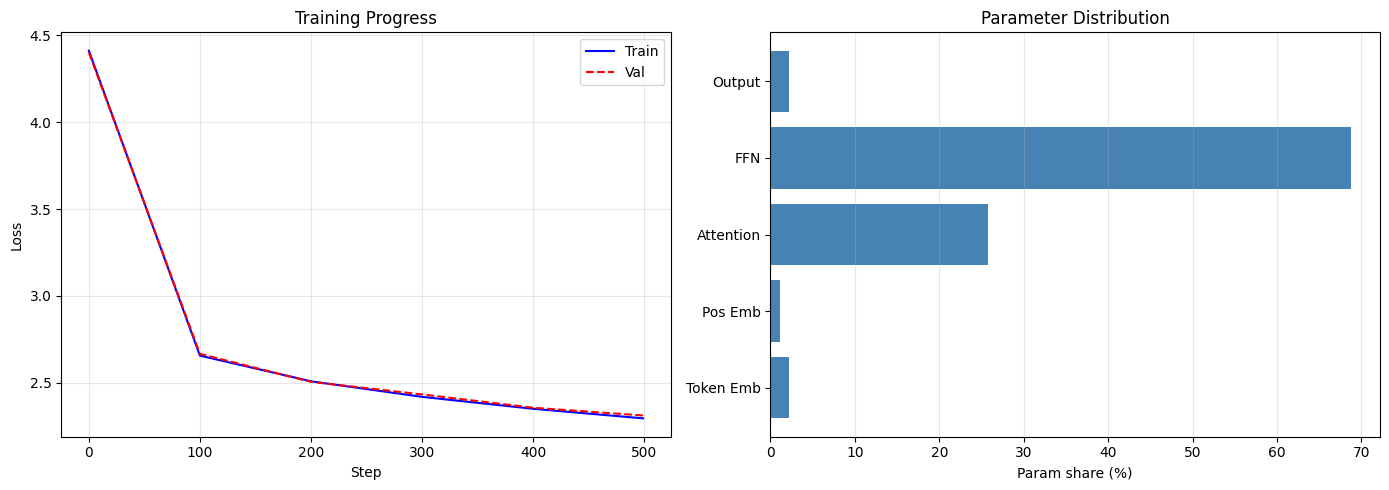

Train loss: 4.4116 -> 2.2959
Val   loss: 4.4022 -> 2.3123


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(steps_log, train_losses, 'b-', label='Train')
axes[0].plot(steps_log, val_losses, 'r--', label='Val')
axes[0].set(xlabel='Step', ylabel='Loss', title='Training Progress')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

layers = {
    'Token Emb': vocab_size * n_embd,
    'Pos Emb': block_size * n_embd,
    'Attention': n_layer * 3 * n_embd * n_embd,
    'FFN': n_layer * 2 * n_embd * 4 * n_embd,
    'Output': n_embd * vocab_size,
}
total = sum(layers.values())
axes[1].barh(list(layers.keys()), [v / total * 100 for v in layers.values()], color='steelblue')
axes[1].set(xlabel='Param share (%)', title='Parameter Distribution')
axes[1].grid(True, alpha=0.3, axis='x')
plt.tight_layout()
plt.show()

print(f"Train loss: {train_losses[0]:.4f} -> {train_losses[-1]:.4f}")
print(f"Val   loss: {val_losses[0]:.4f} -> {val_losses[-1]:.4f}")


In [22]:
context = torch.zeros((1, 1), dtype=torch.long, device=device)
generated = decode(model.generate(context, max_new_tokens=500)[0].tolist())
print('生成文本:')
print('-' * 60)
print(generated[:800])
print('-' * 60)


生成文本:
------------------------------------------------------------

Thoru wiis, zunear nid's Anemer,
Bo nderdnsirs rin, bra st fo Ondeal you oy. thew ungut midsch;
Wrthelomse dy ppay be yooow pprel wimegearp;
Me deerene deios wis fo arendes I li;
Aiveso,
Nf aang de.' cake wester wil ot dreciory therte the a thrarep, in heonn ie sean it thatir tha
vere da a,ol sea but indespo asethme?


Poor, BEThaller that witwtined, he toy Los dovy titugere, einder is enand the mar das cin tho tfay
Msere our te alo thin bus my be cand
Fry go mo put ifokne'sng ap ceang bee od 'C
------------------------------------------------------------


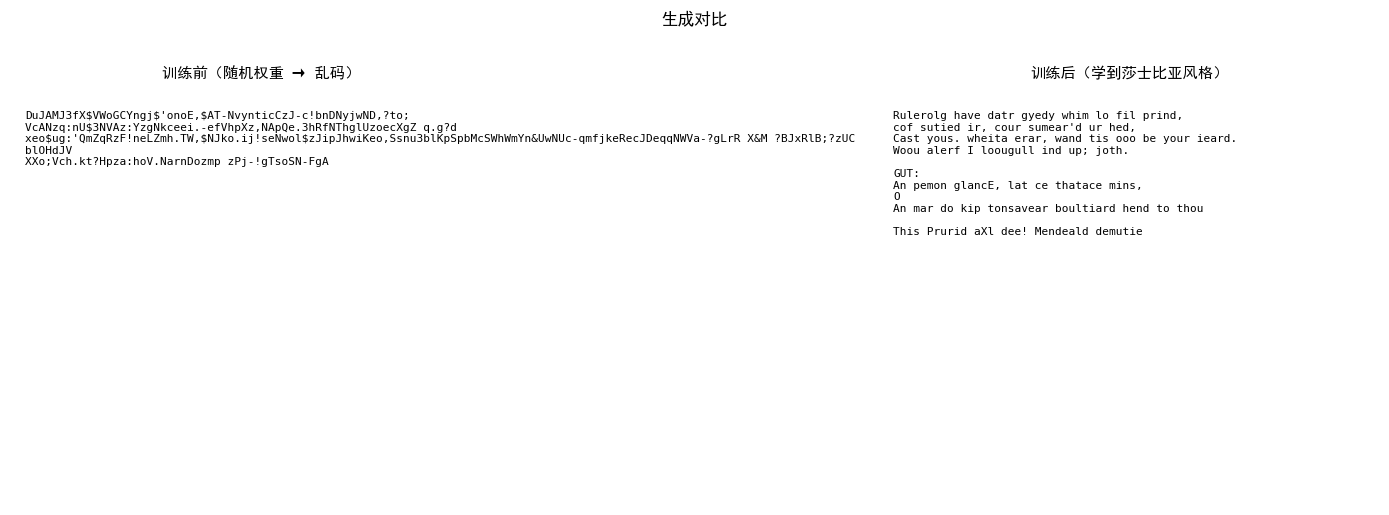

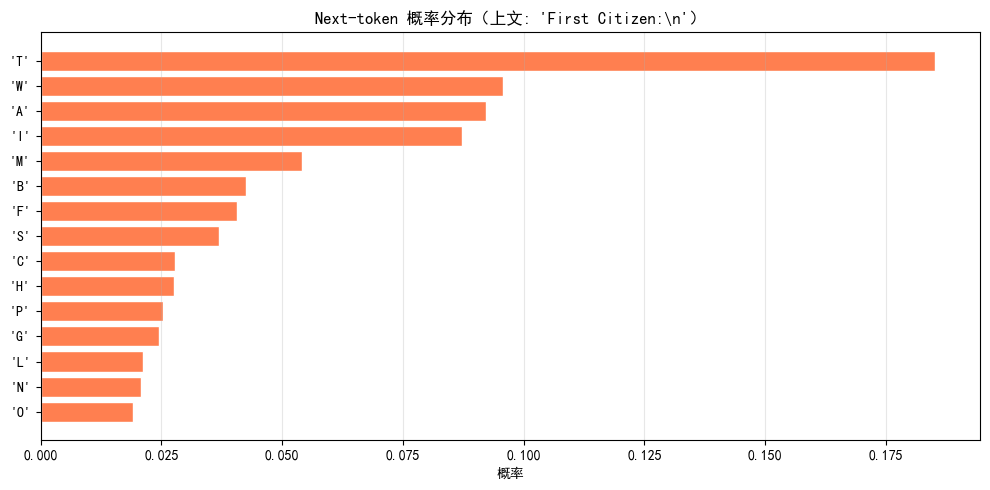

模型最看好的下一个字符: 'T' （p=0.185）


In [27]:
# ── 1. 训练前 vs 训练后生成对比 ──
import matplotlib
# 只指定一个常见中文字体，若不可用则继续默认字体
matplotlib.rcParams['font.sans-serif'] = ['SimHei']
matplotlib.rcParams['axes.unicode_minus'] = False

torch.manual_seed(1337)
model_untrained = GPT().to(device)
gen_ctx = torch.zeros((1, 1), dtype=torch.long, device=device)
n_gen = 300

text_before = decode(model_untrained.generate(gen_ctx.clone(), n_gen)[0].tolist())
text_after = decode(model.generate(gen_ctx.clone(), n_gen)[0].tolist())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, title, text in [
    (axes[0], '训练前（随机权重 → 乱码）', text_before),
    (axes[1], '训练后（学到莎士比亚风格）', text_after),
]:
    ax.text(0.03, 0.97, text[:350], transform=ax.transAxes, fontsize=8,
            va='top', family='monospace')
    ax.set_title(title, fontsize=11)
    ax.axis('off')
plt.suptitle('生成对比', y=1.02)
plt.tight_layout()
plt.show()

# ── 2. Next-token 概率柱状图 ──
prompt = "First Citizen:\n"
prompt_ids = torch.tensor(encode(prompt), dtype=torch.long, device=device).unsqueeze(0)
model.eval()
with torch.no_grad():
    logits, _ = model(prompt_ids)
    probs = F.softmax(logits[0, -1], dim=-1)

top_k = 15
top_probs, top_idx = torch.topk(probs, top_k)
labels = [repr(itos[i.item()]) for i in top_idx]

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(labels[::-1], top_probs.cpu().numpy()[::-1], color='coral', edgecolor='white')
ax.set_xlabel('概率')
ax.set_title(f'Next-token 概率分布（上文: {repr(prompt)}）')
ax.grid(True, alpha=0.3, axis='x')
plt.tight_layout()
plt.show()

print('模型最看好的下一个字符:', repr(itos[top_idx[0].item()]),
      f'（p={top_probs[0].item():.3f}）')

